<a href="https://colab.research.google.com/github/Mondayszz/PORTOFOLIO/blob/main/Back%20to%20Nature%3A%20A%20Real-time%20System%20for%20Indonesian%20Medicinal%20Plant%20Identification%20Using%20Convolutional%20Neural%20Network%20as%20an%20Effort%20to%20Strengthen%20Traditional%20Medicine_Fix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mengimport Pustaka

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import matplotlib.pyplot as plt
from keras.preprocessing import image
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import accuracy_score, confusion_matrix, accuracy_score
from sklearn.model_selection import StratifiedKFold, KFold, RepeatedKFold, train_test_split

# Mempersiapkan Data dan Gdrive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train = pd.read_csv('/content/drive/MyDrive/PROJECT_CNN/data_tumbuhan.csv')
train.head()

,Image,Class
0,1.jpg,Lengkuas
1,2.jpg,Lengkuas
2,3.jpg,Lengkuas
3,4.jpg,Lengkuas
4,5.jpg,Lengkuas


In [ ]:
df = train
TRAIN_PATH = '/content/drive/MyDrive/PROJECT_CNN/DATASET'

# Persiapkan fungsi untuk Training nantinya

In [ ]:
def get_model(IMG_SIZE):
    model = tf.keras.models.Sequential([
    #first_convolution
    tf.keras.layers.Conv2D(16, (3,3), activation='relu', input_shape=(150, 150, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),
    #second_convolution
    tf.keras.layers.Conv2D(32, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    #third_convolution
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    #fourth_convolution
    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax')
])

    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model
#     model.summary()

In [ ]:
# Storing the average of all predictions
main_pred = []
error = []
data_kfold = pd.DataFrame()

In [ ]:
# Creating X, Y for training
train_y = df.Class
train_x = df.drop(['Class'],axis=1)

In [ ]:
IMG_SIZE = 150
BATCH_SIZE = 32
EPOCHS = 25
N_SPLIT = 3

In [ ]:
# Define per-fold score containers
acc_per_fold = []
loss_per_fold = []

# Lakukan training setelah persiapan fungsi dan data

Found 669 validated image filenames belonging to 4 classes.
Found 335 validated image filenames belonging to 4 classes.
Epoch 1/25
20/20 [==============================] - 38s 2s/step - loss: 1.1010 - accuracy: 0.4516 - val_loss: 0.7028 - val_accuracy: 0.6388
Epoch 2/25
20/20 [==============================] - 38s 2s/step - loss: 0.5519 - accuracy: 0.6735 - val_loss: 0.5268 - val_accuracy: 0.7045
Epoch 3/25
20/20 [==============================] - 38s 2s/step - loss: 0.4327 - accuracy: 0.7284 - val_loss: 0.5272 - val_accuracy: 0.7164
Epoch 4/25
20/20 [==============================] - 36s 2s/step - loss: 0.4161 - accuracy: 0.7630 - val_loss: 0.4039 - val_accuracy: 0.7552
Epoch 5/25
20/20 [==============================] - 36s 2s/step - loss: 0.3954 - accuracy: 0.7614 - val_loss: 0.4270 - val_accuracy: 0.7313
Epoch 6/25
20/20 [==============================] - 37s 2s/step - loss: 0.3914 - accuracy: 0.7645 - val_loss: 0.4340 - val_accuracy: 0.7463
Epoch 7/25
20/20 [======================

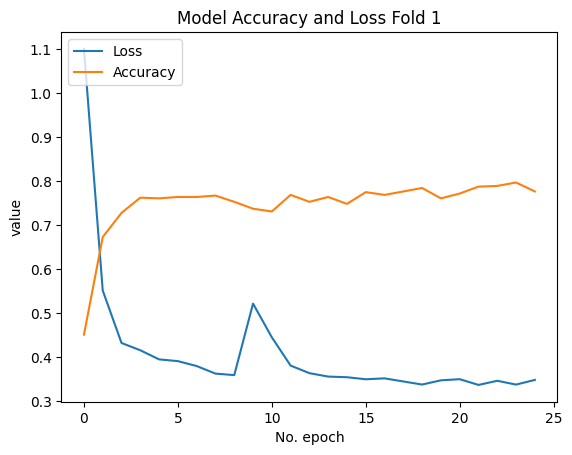

11/11 [==============================] - 7s 645ms/step


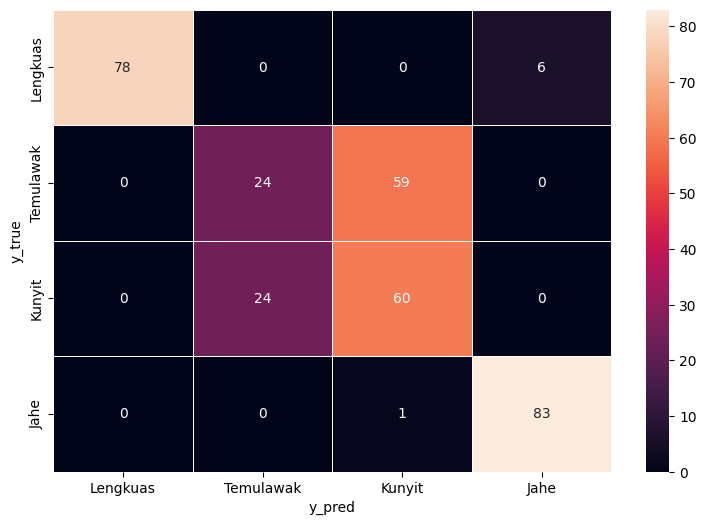

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Score for fold 1: loss of 0.5017492175102234; accuracy of 73.13432693481445%
Found 669 validated image filenames belonging to 4 classes.
Found 335 validated image filenames belonging to 4 classes.
Epoch 1/25
20/20 [==============================] - 38s 2s/step - loss: 0.9860 - accuracy: 0.4929 - val_loss: 0.4697 - val_accuracy: 0.7164
Epoch 2/25
20/20 [==============================] - 38s 2s/step - loss: 0.5193 - accuracy: 0.7017 - val_loss: 0.4410 - val_accuracy: 0.7403
Epoch 3/25
20/20 [==============================] - 39s 2s/step - loss: 0.4316 - accuracy: 0.7535 - val_loss: 0.4051 - val_accuracy: 0.7463
Epoch 4/25
20/20 [==============================] - 37s 2s/step - loss: 0.4521 - accuracy: 0.7206 - val_loss: 0.5051 - val_accuracy: 0.7075
Epoch 5/25
20/20 [==============================] - 38s 2s/step - loss: 0.4493 - accuracy: 0.7253 - val_loss: 0.5417 - val_accuracy: 0.7134
Epoch 6/25
20/20 [==============================] - 36s 2s/step - loss: 0.4235 - accuracy: 0.7441 - val

In [ ]:
#Initializing Data Generators
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
validation_datagen = ImageDataGenerator(rescale = 1./255)

# k-fold
kfold = StratifiedKFold(n_splits=N_SPLIT,shuffle=True,random_state=42)

# Variable for keeping count of split we are executing
j = 0

# K-fold Train and test for each split
for train_idx, val_idx in list(kfold.split(train_x,train_y)):
    x_train_df = df.iloc[train_idx]
    x_valid_df = df.iloc[val_idx]
    j+=1


    training_set = train_datagen.flow_from_dataframe(dataframe=x_train_df, directory=TRAIN_PATH,
                                                 x_col="Image", y_col="Class",
                                                 class_mode="categorical",
                                                 target_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE)

    validation_set = validation_datagen.flow_from_dataframe(dataframe=x_valid_df, directory=TRAIN_PATH,
                                                 x_col="Image", y_col="Class",
                                                 class_mode="categorical",
                                                 shuffle=False,
                                                 target_size=(IMG_SIZE,IMG_SIZE), batch_size=BATCH_SIZE)

    model = get_model(IMG_SIZE)


    history = model.fit(training_set,
                        validation_data=validation_set,
                        epochs = EPOCHS,
                        steps_per_epoch=x_train_df.shape[0] // BATCH_SIZE
                        )

    plt.plot(history.history['loss'], label='Loss')
    plt.plot(history.history['accuracy'], label='Accuracy')
    plt.title(f'Model Accuracy and Loss Fold {j}')
    plt.ylabel('value')
    plt.xlabel('No. epoch')
    plt.legend(loc="upper left")
    plt.show()

    scores = model.evaluate(validation_set, verbose=0)

    pred = model.predict(validation_set)
    y_pred = np.argmax(pred, axis=1)

    cf_matrix = confusion_matrix(validation_set.classes, y_pred)
    import seaborn as sns
    f, ax = plt.subplots(figsize=(9, 6))
    sns.heatmap(cf_matrix, annot=True, fmt="d", linewidths=.5, ax=ax)
    plt.xlabel("y_pred")
    plt.ylabel("y_true")
    ax.xaxis.set_ticklabels(['Lengkuas', 'Temulawak','Kunyit','Jahe'])
    ax.yaxis.set_ticklabels(['Lengkuas', 'Temulawak','Kunyit','Jahe'])
    plt.show()

    model.save(f'/content/drive/MyDrive/PROJECT_CNN/model_r/model_new{j}.h5')
    print(f'Score for fold {j}: {model.metrics_names[0]} of {scores[0]}; {model.metrics_names[1]} of {scores[1]*100}%')
    acc_per_fold.append(scores[1] * 100)
    loss_per_fold.append(scores[0])

In [ ]:
print('Score per fold')
for i in range(0, len(acc_per_fold)):
  print(f'> Fold {i+1} - Loss: {loss_per_fold[i]} - Accuracy: {acc_per_fold[i]}%')
print('Average scores for all folds:')
print(f'> Accuracy: {np.mean(acc_per_fold)} ')
print(f'> Loss: {np.mean(loss_per_fold)}')

Score per fold
> Fold 1 - Loss: 0.5963301062583923 - Accuracy: 76.11940503120422%
> Fold 2 - Loss: 0.5729793906211853 - Accuracy: 71.1442768573761%
> Fold 3 - Loss: 0.45674240589141846 - Accuracy: 75.62189102172852%
> Fold 4 - Loss: 0.42269593477249146 - Accuracy: 79.10447716712952%
> Fold 5 - Loss: 0.4037546217441559 - Accuracy: 73.50000143051147%
Average scores for all folds:
> Accuracy: 75.09801030158997 
> Loss: 0.4905004918575287
